# `Geocroissant` to OGC TrainingDML-AI (TDML) Conversion 🥐

## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">This notebook demonstrates how to convert Earth observation machine learning datasets described in <a href="https://github.com/mlcommons/croissant">GeoCroissant</a> format into compliant <a href="https://www.ogc.org/standards/trainingdml-ai">OGC TrainingDML-AI (OGC 20-057r1)</a> metadata using <a href="https://github.com/TrainingDML/pytdml">pytdml</a>.</p>
    <p>We use NASA and IBM's <a href="https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars">HLS Burn Scars dataset</a>, which pairs multi-spectral satellite imagery from Harmonized Landsat Sentinel-2 (HLS) with ground truth wildfire burn scar masks.</p>
  </div>
  <img src="../../assets/geocr.jpg" alt="GeoCroissant" width="115" style="border-radius: 8px; flex-shrink: 0;">
</div>

### GeoCroissant to OGC TrainingDML-AI Mapping

| GeoCroissant Field | OGC TrainingDML-AI Field | Standard Class / Type | Description |
| :--- | :--- | :--- | :--- |
| `name` / `@id` | `id` & `name` | `AI_EOTrainingDataset.id`, `name` | Dataset identifier and human-readable title |
| `description` | `description` | `AI_EOTrainingDataset.description` | Detailed dataset description |
| `license` | `license` | `AI_EOTrainingDataset.license` | Licensing terms (e.g. `CC-BY-4.0`) |
| `version` | `version` | `AI_EOTrainingDataset.version` | Dataset release version |
| `keywords` | `keywords` | `AI_EOTrainingDataset.keywords` | Topical discovery keywords |
| `creator` | `providers` | `AI_EOTrainingDataset.providers` | Organizations responsible for dataset production (NASA, IBM) |
| `datePublished` | `createdTime` / `updatedTime` | `AI_EOTrainingDataset.createdTime` | Dataset publication timestamp |
| `geocr:coordinateReferenceSystem` | `dataSources` (`CI_Citation`) | `CI_Citation` with CRS identifier | Spatial Coordinate Reference System citation (EPSG:32610) |
| `spatialCoverage` (`Place` / `GeoShape` box) | `extent` | `AI_EOTrainingDataset.extent` | Bounding box `[west, south, east, north]` |
| `geocr:spectralBandMetadata` | `bands` | `List[MD_Band]` (ISO 19115-1) | Spectral band names, center wavelengths, bandwidths, and units |
| `geocr:spatialResolution` & sampling | `statisticsInfo` | `List[NamedValue]` | Ground resolution (30m), temporal resolution, sampling strategy |
| Task description / ML problem | `tasks` | `List[AI_EOTask]` | Training task definition (`taskType="Semantic Segmentation"`) |
| Classes / Target categories | `classes` & `numberOfClasses` | `List[NamedValue]` & `int` | Category dictionary mapping class names (`background`, `burn_scar`) |
| `recordSet` (`train_examples`, `valid_examples`) | `data` | `List[AI_EOTrainingData]` | Individual training and validation sample entries |
| Sample splits (`train_examples` vs `valid_examples`) | `trainingType` | `AI_TrainingTypeCode` (`"training"` vs `"validation"`) | Split partition indicator conforming to OGC enum |
| Input imagery (`train/images/*.tif`) | `dataURL` | `AI_EOTrainingData.dataURL` | URI/path to multi-band GeoTIFF image |
| Ground truth mask (`train/masks/*.tif`) | `labels` | `List[AI_PixelLabel]` | Pixel-level semantic segmentation mask URL and format (`image/tiff`) |

In [1]:
#!pip install mlcroissant pytdml rasterio torch matplotlib jsonschema

import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import glob
import json
import os
import sys
from typing import Dict, List, Optional

# Ensure local pytdml repository is in sys.path
pytdml_dir = os.path.abspath(os.path.join(os.getcwd(), "../../pytdml"))
if os.path.exists(pytdml_dir) and pytdml_dir not in sys.path:
    sys.path.insert(0, pytdml_dir)

from jsonschema import Draft7Validator, RefResolver
import matplotlib.pyplot as plt
import mlcroissant as mlc
from mlcroissant._src.core.constants import CROISSANT_CACHE
import numpy as np
from PIL import Image
import rasterio
import torch
from torch.utils.data import DataLoader, Dataset

import pytdml
from pytdml.io import read_from_json, write_to_json
from pytdml.type import (
    AI_EOTask,
    AI_EOTrainingData,
    AI_PixelLabel,
    CI_Citation,
    EOTrainingDataset,
    MD_Band,
    MD_Identifier,
    NamedValue,
)

print("Libraries imported successfully.")
print(f"pytdml version: {pytdml.__version__}")

Libraries imported successfully.
pytdml version: 1.2.0


## 1. Load GeoCroissant metadata

We load the GeoCroissant metadata file (`hls_burn_scars.json`) and inspect the remote sensing attributes, coordinate reference system, and spectral band configuration:

In [2]:
json_path = "hls_burn_scars.json"
with open(json_path, "r", encoding="utf-8") as f:
    gc = json.load(f)

print(f"Dataset Name: {gc.get('name')}")
print(f"Conforms To:  {gc.get('conformsTo')}")
print(f"License:      {gc.get('license')}")
print(f"CRS:          {gc.get('geocr:coordinateReferenceSystem')}")

spatial_box = gc.get("spatialCoverage", {}).get("geo", {}).get("box")
print(f"Spatial Box:  {spatial_box}")

band_names = gc.get("geocr:bandConfiguration", {}).get("geocr:bandNamesList", [])
print(f"Bands ({len(band_names)}):     {band_names}")

record_set_names = [rs.get("name") for rs in gc.get("recordSet", [])]
print(f"RecordSets:   {record_set_names}")

Dataset Name: hls-burn-scars
Conforms To:  ['http://mlcommons.org/croissant/1.1', 'http://mlcommons.org/croissant/RAI/', 'http://mlcommons.org/croissant/geo/']
License:      CC BY-SA 4.0
CRS:          EPSG:32610
Spatial Box:  24.396308 -124.848974 49.384358 -66.885444
Bands (6):     ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
RecordSets:   ['train images', 'train masks', 'train examples', 'valid images', 'valid masks', 'valid examples']


## 2. Convert GeoCroissant to OGC TrainingDML-AI

We map the GeoCroissant JSON-LD structure into an OGC `EOTrainingDataset` object. The converter translates spectral band metadata into ISO 19115-1 `MD_Band` objects, reprojects the bounding box to `[west, south, east, north]`, attaches CRS citations, and structures training and validation samples into `AI_EOTrainingData` entries with `AI_PixelLabel`:

In [3]:
def geocroissant_to_tdml(
    gc_json: Dict, data_dir: Optional[str] = None
) -> EOTrainingDataset:
    """Converts a GeoCroissant dataset dictionary into an OGC-compliant EOTrainingDataset."""
    dataset_id = gc_json.get("name", "dataset")
    name = gc_json.get("name", "Dataset").replace("-", " ").title()
    description = gc_json.get("description", "")
    license_str = (
        "CC-BY-4.0"
        if "creativecommons.org" in gc_json.get("license", "")
        else gc_json.get("license", "Unknown")
    )
    version = str(gc_json.get("version", "1.0.0"))
    created_time = gc_json.get("datePublished", "2024-01-01")

    # Providers
    creator = gc_json.get("creator", ["NASA", "IBM"])
    if isinstance(creator, list):
        providers = [c.get("name") if isinstance(c, dict) else str(c) for c in creator]
    elif isinstance(creator, dict):
        providers = [creator.get("name", "NASA")]
    elif isinstance(creator, str):
        providers = [creator]
    else:
        providers = ["NASA", "IBM"]

    # Keywords
    keywords = gc_json.get(
        "keywords", ["earth observation", "remote sensing", "burn scars"]
    )

    # Spatial extent: GeoCroissant uses 'min_lat min_lon max_lat max_lon'
    box_str = gc_json.get("spatialCoverage", {}).get("geo", {}).get("box", "")
    if box_str:
        lat1, lon1, lat2, lon2 = map(float, box_str.split())
        extent = [lon1, lat1, lon2, lat2]  # [west, south, east, north]
    else:
        extent = [-180.0, -90.0, 180.0, 90.0]

    # Spectral bands: ISO 19115-1 MD_Band
    bands = []
    band_meta_list = gc_json.get("geocr:spectralBandMetadata", [])
    if band_meta_list:
        for b in band_meta_list:
            b_name = b.get("name")
            cw = b.get("geocr:centerWavelength", {})
            bw = b.get("geocr:bandwidth", {})
            c_val = (
                float(cw.get("value"))
                if isinstance(cw, dict) and cw.get("value") is not None
                else None
            )
            bw_val = (
                float(bw.get("value"))
                if isinstance(bw, dict) and bw.get("value") is not None
                else None
            )
            units = cw.get("unitText", "nm") if isinstance(cw, dict) else "nm"

            b_min = (
                (c_val - bw_val / 2.0)
                if (c_val is not None and bw_val is not None)
                else None
            )
            b_max = (
                (c_val + bw_val / 2.0)
                if (c_val is not None and bw_val is not None)
                else None
            )

            bands.append(
                MD_Band(
                    name=[MD_Identifier(code=b_name)],
                    peak_response=c_val,
                    bound_min=b_min,
                    bound_max=b_max,
                    bound_units=units,
                    units=units,
                )
            )
    else:
        for b_name in gc_json.get("geocr:bandConfiguration", {}).get(
            "geocr:bandNamesList", []
        ):
            bands.append(MD_Band(name=[MD_Identifier(code=b_name)]))

    # Citations & Data Sources
    data_sources = []
    for dist in gc_json.get("distribution", []):
        if dist.get("contentUrl"):
            data_sources.append(
                CI_Citation(
                    title=dist.get("name", name),
                    alternate_title=[dist.get("contentUrl")],
                )
            )

    crs_code = gc_json.get("geocr:coordinateReferenceSystem")
    if crs_code:
        data_sources.append(
            CI_Citation(
                title=f"Coordinate Reference System ({crs_code})",
                alternate_title=[crs_code],
            )
        )

    # Task: Semantic Segmentation
    tasks = [
        AI_EOTask(
            id=f"{dataset_id}-segmentation-task",
            type="AI_EOTask",
            task_type="Semantic Segmentation",
            description=(
                "Semantic segmentation of wildfire burn scars from multi-spectral HLS"
                " satellite imagery"
            ),
        )
    ]

    # Classes: Background and Burn Scar
    classes = [
        NamedValue(key="background", value="0"),
        NamedValue(key="burn_scar", value="1"),
    ]

    # Discover and build training data entries
    data_items = []
    if data_dir and os.path.exists(data_dir):
        for split, training_type in [("train", "training"), ("valid", "validation")]:
            img_pattern = os.path.join(data_dir, split, "images", "*_merged.tif")
            for img_path in sorted(glob.glob(img_pattern)):
                fname = os.path.basename(img_path)
                key = fname.replace("_merged.tif", "")
                mask_rel = f"{split}/masks/{key}.mask.tif"
                img_rel = f"{split}/images/{fname}"

                data_items.append(
                    AI_EOTrainingData(
                        type="AI_EOTrainingData",
                        id=key,
                        training_type=training_type,
                        data_url=[img_rel],
                        labels=[
                            AI_PixelLabel(
                                type="AI_PixelLabel",
                                image_url=[mask_rel],
                                image_format=["image/tiff"],
                            )
                        ],
                    )
                )

    return EOTrainingDataset(
        id=dataset_id,
        name=name,
        description=description,
        license=license_str,
        version=version,
        created_time=created_time,
        providers=providers,
        keywords=keywords,
        data_sources=data_sources,
        tasks=tasks,
        classes=classes,
        number_of_classes=len(classes),
        bands=bands,
        extent=extent,
        image_size="512,512,6",
        data=data_items,
        amount_of_training_data=len(data_items),
        type="AI_EOTrainingDataset",
    )


# Locate local extracted data cache or trigger download via mlcroissant
extract_dirs = glob.glob(os.path.join(CROISSANT_CACHE, "extract/*/train/images"))
if not extract_dirs:
    # Trigger mlcroissant extraction
    _ = mlc.Dataset(jsonld=json_path)
    extract_dirs = glob.glob(os.path.join(CROISSANT_CACHE, "extract/*/train/images"))

data_dir = os.path.dirname(os.path.dirname(extract_dirs[0])) if extract_dirs else None
print(f"Data root directory: {data_dir}")

# Convert GeoCroissant to OGC-TDML
tdml_dataset = geocroissant_to_tdml(gc, data_dir=data_dir)

print(f"\nSuccessfully created OGC EOTrainingDataset: {tdml_dataset.name}")
print(f"Total training data records: {tdml_dataset.amount_of_training_data}")
train_count = sum(1 for d in tdml_dataset.data if d.training_type == "training")
valid_count = sum(1 for d in tdml_dataset.data if d.training_type == "validation")
print(f"Training split:   {train_count} samples")
print(f"Validation split: {valid_count} samples")

Data root directory: /home/xuan/.cache/croissant/extract/d7e131056f09b43efd7e11111a67a00a29b69b47f3f9763eb9bea9d5b70971da

Successfully created OGC EOTrainingDataset: Hls Burn Scars
Total training data records: 804
Training split:   540 samples
Validation split: 264 samples


## 3. Serialize and validate OGC-TDML metadata

We serialize the `EOTrainingDataset` object to standard JSON using `pytdml.io.write_to_json` and validate it against the official OGC TrainingDML-AI 1.0 JSON Schema:

In [4]:
tdml_output_file = "hls_burn_scars_tdml.json"
write_to_json(tdml_dataset, tdml_output_file)
file_size_kb = os.path.getsize(tdml_output_file) / 1024
print(f"Serialized TDML saved to: {tdml_output_file} ({file_size_kb:.1f} KB)")

# Validate against official OGC TrainingDML-AI JSON Schema
schema_dir = os.path.abspath("../../TrainingDML-AI_SWG-main/schemas/1.0/json_schema")
main_schema_file = os.path.join(schema_dir, "ai_eoTrainingDataset.json")

with open(main_schema_file, "r", encoding="utf-8") as f:
    schema = json.load(f)

# Build schema store for resolving cross-schema references locally
schema_store = {}
for fname in os.listdir(schema_dir):
    if fname.endswith(".json"):
        with open(os.path.join(schema_dir, fname), "r", encoding="utf-8") as sf:
            s_content = json.load(sf)
            sid = s_content.get("$id")
            if sid:
                schema_store[sid] = s_content

resolver = RefResolver(
    base_uri=schema.get("$id", ""), referrer=schema, store=schema_store
)
validator = Draft7Validator(schema, resolver=resolver)

with open(tdml_output_file, "r", encoding="utf-8") as f:
    tdml_instance = json.load(f)

validation_errors = list(validator.iter_errors(tdml_instance))
print(f"Validation errors count: {len(validation_errors)}")

if len(validation_errors) == 0:
    print(
        "SUCCESS: Generated file strictly conforms to OGC TrainingDML-AI 1.0"
        " (AI_EOTrainingDataset)."
    )
else:
    for err in validation_errors[:5]:
        print(f"Error at {list(err.path)}: {err.message}")

Serialized TDML saved to: hls_burn_scars_tdml.json (586.6 KB)
Validation errors count: 0
SUCCESS: Generated file strictly conforms to OGC TrainingDML-AI 1.0 (AI_EOTrainingDataset).


## 4. Load and inspect OGC-TDML metadata with PyTDML

We reload the generated OGC-TDML file purely from disk using `pytdml.io.read_from_json` to confirm standard interoperability:

In [5]:
reloaded_tdml = read_from_json(tdml_output_file)

print(f"Loaded ID:          {reloaded_tdml.id}")
print(f"Loaded Name:        {reloaded_tdml.name}")
print(f"License:            {reloaded_tdml.license}")
print(f"Extent:             {reloaded_tdml.extent}")
print(f"Image Size:         {reloaded_tdml.image_size}")
print(f"Number of Classes:  {reloaded_tdml.number_of_classes}")
print(f"Classes:            {[(c.key, c.value) for c in reloaded_tdml.classes]}")
print(f"Task Type:          {reloaded_tdml.tasks[0].task_type}")

print(f"\nSpectral Bands ({len(reloaded_tdml.bands)}):")
for b in reloaded_tdml.bands:
    name_code = b.name[0].code if b.name else "unknown"
    print(
        f"  Band: {name_code:5s} | Peak: {b.peak_response} {b.units} | Range:"
        f" [{b.bound_min}, {b.bound_max}] {b.bound_units}"
    )

sample_0 = reloaded_tdml.data[0]
print(f"\nFirst Sample ({sample_0.id}):")
print(f"  Training Type: {sample_0.training_type}")
print(f"  Data URL:      {sample_0.data_url[0]}")
print(f"  Mask URL:      {sample_0.labels[0].image_url[0]}")
print(f"  Mask Format:   {sample_0.labels[0].image_format[0]}")

Loaded ID:          hls-burn-scars
Loaded Name:        Hls Burn Scars
License:            CC BY-SA 4.0
Extent:             [-124.848974, 24.396308, -66.885444, 49.384358]
Image Size:         512,512,6
Number of Classes:  2
Classes:            [('background', '0'), ('burn_scar', '1')]
Task Type:          Semantic Segmentation

Spectral Bands (6):
  Band: Blue  | Peak: 490.0 nm | Range: [457.5, 522.5] nm
  Band: Green | Peak: 560.0 nm | Range: [530.0, 590.0] nm
  Band: Red   | Peak: 665.0 nm | Range: [650.0, 680.0] nm
  Band: NIR   | Peak: 865.0 nm | Range: [850.0, 880.0] nm
  Band: SWIR1 | Peak: 1610.0 nm | Range: [1565.0, 1655.0] nm
  Band: SWIR2 | Peak: 2200.0 nm | Range: [2110.0, 2290.0] nm

First Sample (subsetted_512x512_HLS.S30.T10SDH.2020248.v1.4):
  Training Type: training
  Data URL:      train/images/subsetted_512x512_HLS.S30.T10SDH.2020248.v1.4_merged.tif
  Mask URL:      train/masks/subsetted_512x512_HLS.S30.T10SDH.2020248.v1.4.mask.tif
  Mask Format:   image/tiff


## 5. Stream training data into PyTorch

We construct a PyTorch `Dataset` that consumes the parsed OGC-TDML representation. Each record's `data_url` points to the multi-band GeoTIFF, and `labels[0].image_url` points to the binary burn scar mask:

In [6]:
class TDMLBurnScarsDataset(Dataset):
    """PyTorch Dataset consuming OGC-TDML AI_EOTrainingData records."""

    def __init__(
        self,
        tdml_obj: EOTrainingDataset,
        training_type: str = "training",
        root_dir: Optional[str] = None,
    ):
        self.root_dir = root_dir
        self.samples = [
            d
            for d in tdml_obj.data
            if getattr(d, "training_type", None) == training_type
        ]

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        item = self.samples[idx]
        img_rel = item.data_url[0]
        mask_rel = item.labels[0].image_url[0]

        img_path = os.path.join(self.root_dir, img_rel) if self.root_dir else img_rel
        mask_path = os.path.join(self.root_dir, mask_rel) if self.root_dir else mask_rel

        # Read 6 bands via rasterio: Blue (1), Green (2), Red (3), NIR (4), SWIR1 (5), SWIR2 (6)
        with rasterio.open(img_path) as src:
            img = src.read([1, 2, 3, 4, 5, 6])

        # Read binary mask via PIL
        with Image.open(mask_path) as mask_img:
            mask = np.array(mask_img)

        return {
            "id": item.id,
            "image": torch.tensor(img, dtype=torch.float32),
            "mask": torch.tensor(mask, dtype=torch.float32),
        }


# Instantiate PyTorch Datasets for both splits
ds_train = TDMLBurnScarsDataset(
    reloaded_tdml, training_type="training", root_dir=data_dir
)
ds_valid = TDMLBurnScarsDataset(
    reloaded_tdml, training_type="validation", root_dir=data_dir
)

train_loader = DataLoader(ds_train, batch_size=2, shuffle=False)
valid_loader = DataLoader(ds_valid, batch_size=2, shuffle=False)

print(f"Training Dataset size:   {len(ds_train)} items")
print(f"Validation Dataset size: {len(ds_valid)} items")

# Iterate first batch
for batch in train_loader:
    print(f"\nBatch loaded successfully from OGC-TDML:")
    print(f"  Batch sample IDs: {batch['id']}")
    print(
        f"  Image tensor:     shape={batch['image'].shape},"
        f" dtype={batch['image'].dtype}"
    )
    print(
        f"  Mask tensor:      shape={batch['mask'].shape},  dtype={batch['mask'].dtype}"
    )
    break

Training Dataset size:   540 items
Validation Dataset size: 264 items

Batch loaded successfully from OGC-TDML:
  Batch sample IDs: ['subsetted_512x512_HLS.S30.T10SDH.2020248.v1.4', 'subsetted_512x512_HLS.S30.T10SEH.2018245.v1.4']
  Image tensor:     shape=torch.Size([2, 6, 512, 512]), dtype=torch.float32
  Mask tensor:      shape=torch.Size([2, 512, 512]),  dtype=torch.float32


## 6. Visualize satellite imagery and ground truth masks

We visualize three sample scenes streamed from the OGC-TDML dataset:

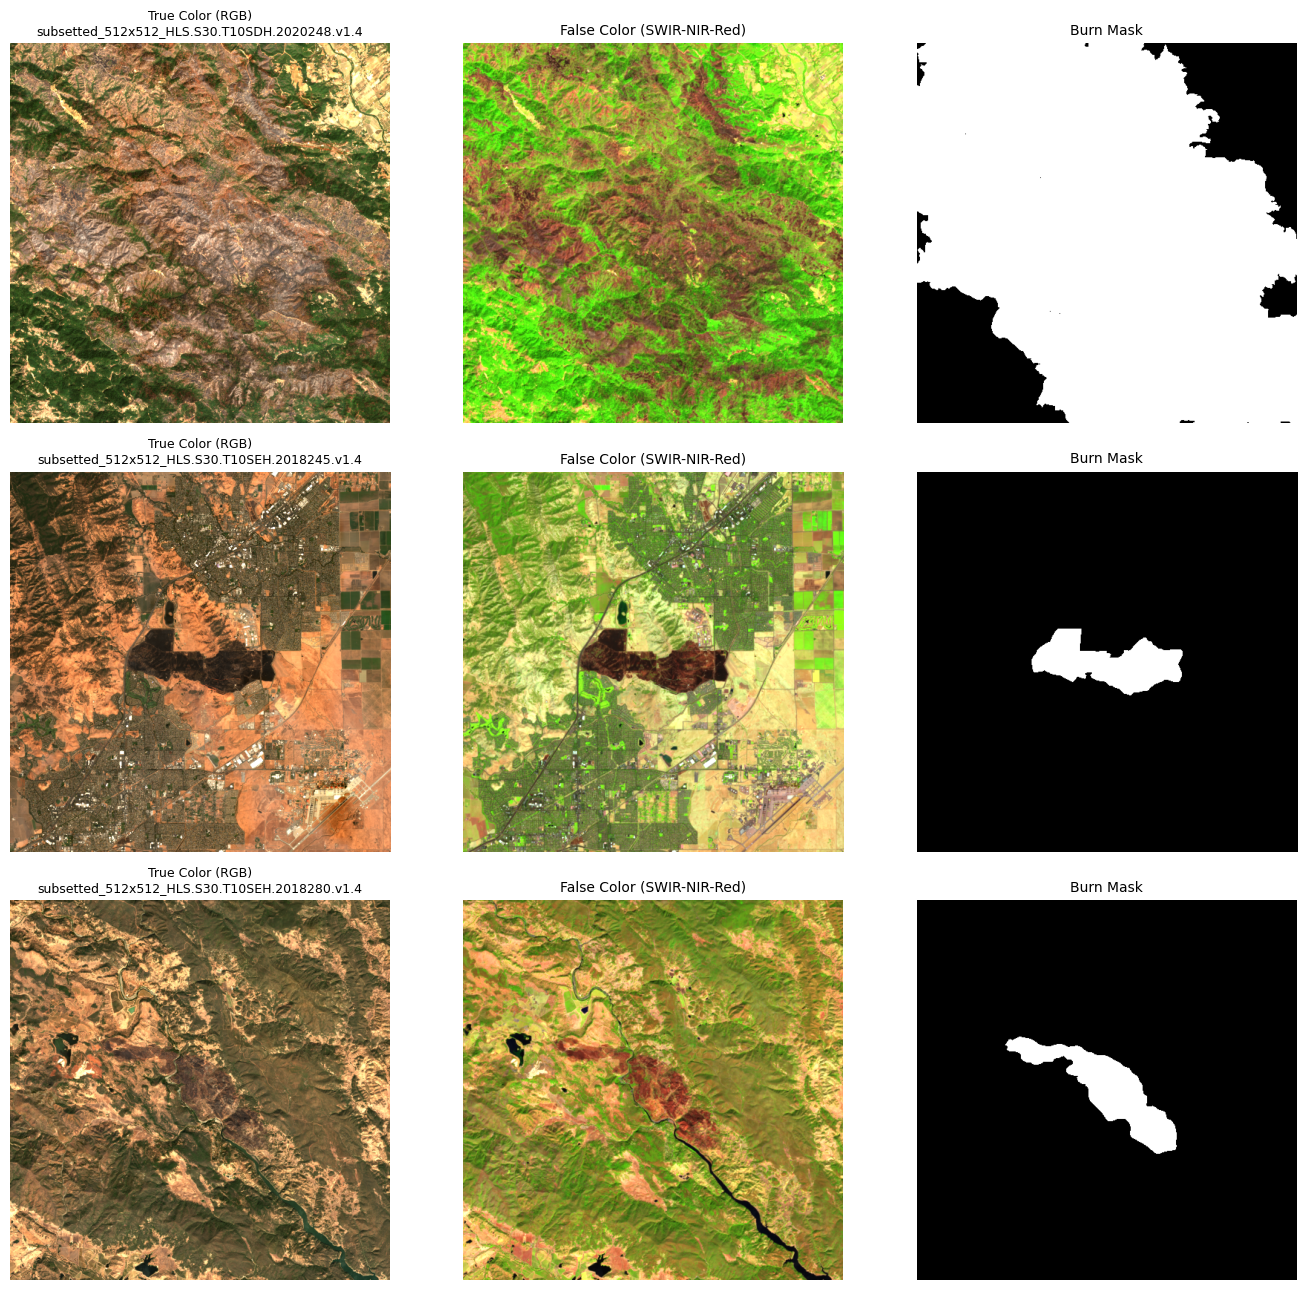

In [8]:
vis_loader = DataLoader(ds_train, batch_size=1, shuffle=False)
samples_to_plot = []

for batch in vis_loader:
    samples_to_plot.append(batch)
    if len(samples_to_plot) >= 3:
        break

fig, axes = plt.subplots(3, 3, figsize=(14, 13), facecolor="white")

for idx, sample in enumerate(samples_to_plot):
    img = sample["image"][0].numpy()  # shape: [6, 512, 512]
    mask = sample["mask"][0].numpy()  # shape: [512, 512]
    sample_id = sample["id"][0]

    # True Color RGB: Bands 3 (Red), 2 (Green), 1 (Blue) -> 0-indexed 2, 1, 0
    rgb = np.transpose(img[[2, 1, 0], :, :], (1, 2, 0))
    # False Color: Bands 5 (SWIR1), 4 (NIR), 3 (Red) -> 0-indexed 4, 3, 2
    fc = np.transpose(img[[4, 3, 2], :, :], (1, 2, 0))

    # Apply 98th percentile clipping for high-contrast visualization
    rgb_vis = np.clip(rgb / np.percentile(rgb, 98), 0, 1)
    fc_vis = np.clip(fc / np.percentile(fc, 98), 0, 1)

    # Binary mask: 1 for burned areas, 0 for background
    mask_bw = (mask > 0).astype(np.uint8)

    # Plot True Color RGB
    axes[idx, 0].imshow(rgb_vis)
    axes[idx, 0].set_title(f"True Color (RGB)\n{sample_id}", fontsize=9, color="black")
    axes[idx, 0].axis("off")

    # Plot False Color Infrared
    axes[idx, 1].imshow(fc_vis)
    axes[idx, 1].set_title("False Color (SWIR-NIR-Red)", fontsize=10, color="black")
    axes[idx, 1].axis("off")

    # Plot Burn Mask
    axes[idx, 2].imshow(mask_bw, cmap="gray", vmin=0, vmax=1)
    burn_pct = 100.0 * (mask_bw.sum() / mask_bw.size)
    axes[idx, 2].set_title(f"Burn Mask", fontsize=10, color="black")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()